This notebook accompanies my note on [forward propagation](index.qmd). It turns the pictures and formulas from that note into code:

1. **The layer as a graph** — the 4→3 fully connected layer from my notes, drawn in 2D and in 3D.
2. **The matrix view** — the same layer as a $3\times4$ weight matrix, with a check that the edge-by-edge sum and the matrix product agree.
3. **Activation functions** — every activation from my notes, plotted with its derivative.
4. **Softmax** — the vector-valued "activation" used at the output of a classifier.

Notation (same as the note): layer 1 has pre-activations $\mathbf{a}_1$ and outputs $f(\mathbf{a}_1)$; layer 2's pre-activations are

$$a_{2,j} = \sum_{i=1}^{4} w_{j,i}\, f(a_{1,i}), \qquad \mathbf{a}_2 = W\, f(\mathbf{a}_1),$$

where $w_{j,i}$ is the weight on the edge **into node $j$** of layer 2 **from node $i$** of layer 1.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

N_IN, N_OUT = 4, 3
# One color per layer-2 node: every edge into node j (= row j of W) shares a color.
ROW_COLORS = ["#d62728", "#2ca02c", "#1f77b4"]

## 1. The layer as a graph

Each of the 4 layer-1 nodes connects to each of the 3 layer-2 nodes, so there are $4 \times 3 = 12$ weights. The edges are colored by their **destination**: all edges into layer-2 node $j$ share a color, and those are exactly the weights $w_{j,1}, \dots, w_{j,4}$ — **row $j$** of the weight matrix.

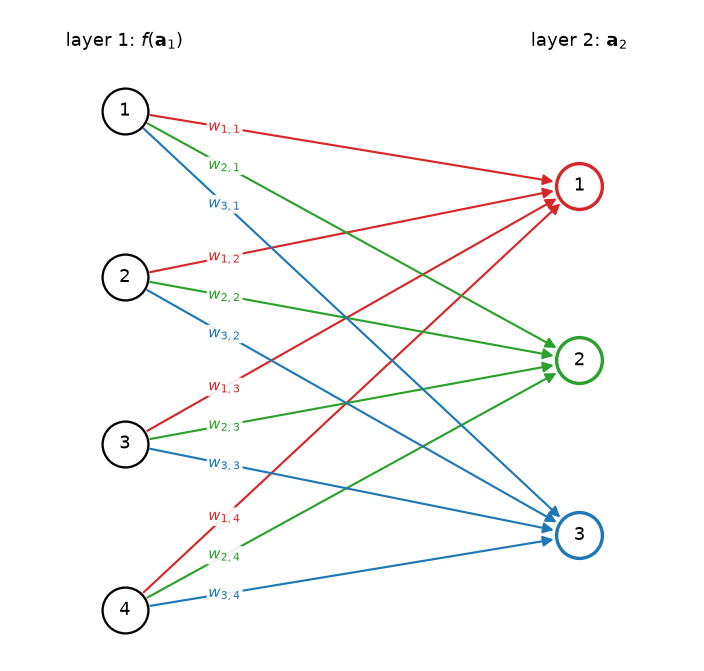

In [2]:
#| label: fig-network-2d
#| fig-cap: "The 4→3 layer in 2D. Edge colors mark the destination node; edge $i \to j$ carries weight $w_{j,i}$."
def layer_positions_2d():
    p_in = np.column_stack([np.zeros(N_IN), np.linspace(1.0, 0.0, N_IN)])
    p_out = np.column_stack([np.ones(N_OUT), np.linspace(0.85, 0.15, N_OUT)])
    return p_in, p_out

def draw_layer_2d(ax, t_label=0.22):
    p_in, p_out = layer_positions_2d()
    for j in range(N_OUT):
        for i in range(N_IN):
            src, dst = p_in[i], p_out[j]
            ax.annotate("", xy=dst, xytext=src,
                        arrowprops=dict(arrowstyle="-|>", color=ROW_COLORS[j], lw=1.4,
                                        shrinkA=17, shrinkB=17, mutation_scale=14))
            # label near the source end, where the three outgoing edges fan apart
            lx, ly = src + t_label * (dst - src)
            ax.text(lx, ly, rf"$w_{{{j+1},{i+1}}}$", color=ROW_COLORS[j], fontsize=10,
                    ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.9))
    for k, (x, y) in enumerate(p_in):
        ax.scatter(x, y, s=900, c="white", edgecolors="k", linewidths=1.5, zorder=3)
        ax.text(x, y, str(k + 1), ha="center", va="center", fontsize=12, zorder=4)
    for k, (x, y) in enumerate(p_out):
        ax.scatter(x, y, s=900, c="white", edgecolors=ROW_COLORS[k], linewidths=2.2, zorder=3)
        ax.text(x, y, str(k + 1), ha="center", va="center", fontsize=12, zorder=4)
    ax.text(0.0, 1.13, r"layer 1: $f(\mathbf{a}_1)$", ha="center", fontsize=12)
    ax.text(1.0, 1.13, r"layer 2: $\mathbf{a}_2$", ha="center", fontsize=12)
    ax.set_xlim(-0.25, 1.25); ax.set_ylim(-0.1, 1.2); ax.axis("off")

fig, ax = plt.subplots(figsize=(6.5, 6.2))
draw_layer_2d(ax)
plt.tight_layout(); plt.show()

The 3D view below turns the two layers at right angles: the four layer-1 nodes form a horizontal **row**, and the three layer-2 nodes form a vertical **column** behind it. It is the same graph — only the layout changed — but it makes the **fully connected** structure easy to see: every node in one plane connects to every node in the other. To keep it readable, only the weights into node 1 (row 1 of $W$) are labeled.

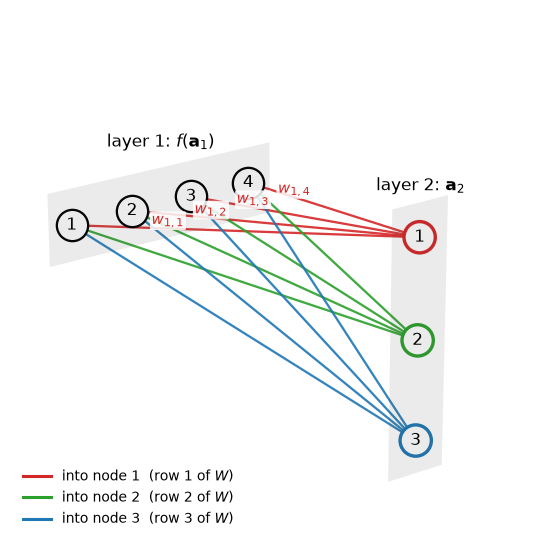

In [3]:
#| label: fig-network-3d
#| fig-cap: "The same layer in 3D: layer 1 as a row, layer 2 as a column. Edges into layer-2 node $j$ share a color (row $j$ of $W$); only row 1 is labeled."
p_in3 = np.array([[0.0, y, 0.0] for y in (-1.2, -0.4, 0.4, 1.2)])          # one row
p_out3 = np.array([[1.0, 0.0, z] for z in (0.9, 0.0, -0.9)])               # one column

fig = plt.figure(figsize=(8, 4.8))
ax = fig.add_subplot(projection="3d")

for x, (hy, hz) in ((0.0, (1.5, 0.35)), (1.0, (0.35, 1.2))):   # translucent layer strips
    yy, zz = np.meshgrid([-hy, hy], [-hz, hz])
    ax.plot_surface(np.full_like(yy, x), yy, zz, color="0.6", alpha=0.10, linewidth=0)

for j in range(N_OUT):
    for i in range(N_IN):
        s, d = p_in3[i], p_out3[j]
        ax.plot(*zip(s, d), color=ROW_COLORS[j], lw=1.5, alpha=0.9)
        if j == 0:
            m = s + 0.3 * (d - s)
            ax.text(*m, rf"$w_{{1,{i+1}}}$", color=ROW_COLORS[0], fontsize=10,
                    ha="center", va="bottom", zorder=12,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.85))

ax.scatter(*p_in3.T, s=420, c="white", edgecolors="k", linewidths=1.5, depthshade=False)
ax.scatter(*p_out3.T, s=420, c="white", edgecolors=ROW_COLORS, linewidths=2.2, depthshade=False)
for k, p in enumerate(p_in3):
    ax.text(*p, str(k + 1), ha="center", va="center", fontsize=11, zorder=10)
for k, p in enumerate(p_out3):
    ax.text(*p, str(k + 1), ha="center", va="center", fontsize=11, zorder=10)
ax.text(0.0, 0.0, 0.55, r"layer 1: $f(\mathbf{a}_1)$", ha="center", fontsize=11)
ax.text(1.0, 0.0, 1.3, r"layer 2: $\mathbf{a}_2$", ha="center", fontsize=11)

for j in range(N_OUT):
    ax.plot([], [], color=ROW_COLORS[j], lw=2, label=rf"into node {j+1}  (row {j+1} of $W$)")
ax.legend(loc="lower left", fontsize=9, frameon=False)
ax.view_init(elev=22, azim=-35)
ax.set_box_aspect((1.6, 1, 1), zoom=1.25); ax.set_axis_off()
fig.subplots_adjust(0, 0, 1, 1); plt.show()

## 2. The matrix view

Stacking the weights so that **row $j$ = all weights into layer-2 node $j$** gives

$$
W = \begin{bmatrix}
w_{1,1} & w_{1,2} & w_{1,3} & w_{1,4} \\
w_{2,1} & w_{2,2} & w_{2,3} & w_{2,4} \\
w_{3,1} & w_{3,2} & w_{3,3} & w_{3,4}
\end{bmatrix} \in \mathbb{R}^{3\times4},
\qquad
\underbrace{\mathbf{a}_2}_{3\times1} = \underbrace{W}_{3\times4}\;\underbrace{f(\mathbf{a}_1)}_{4\times1}.
$$

The index order $w_{j,i}$ (destination first, source second) is what makes this a plain matrix–vector product. Below I compute layer 2 twice — once by looping over the 12 edges, once with `W @ f(a1)` — and check that they match. I use $f = \tanh$ for layer 1 just to have something concrete.

In [4]:
rng = np.random.default_rng(10)
a1 = np.array([0.5, -1.2, 2.0, 0.3])          # layer-1 pre-activations
W = rng.normal(0.0, 0.8, size=(N_OUT, N_IN)).round(2)
f = np.tanh

z1 = f(a1)                                     # layer-1 outputs f(a1)

# Edge by edge: a2_j = sum_i w_{j,i} * f(a1_i)
a2_loop = np.zeros(N_OUT)
for j in range(N_OUT):
    for i in range(N_IN):
        a2_loop[j] += W[j, i] * z1[i]

# All at once: a2 = W f(a1)
a2 = W @ z1

print("W =\n", W)
print("f(a1)        =", z1.round(4))
print("a2 (loop)    =", a2_loop.round(4))
print("a2 (W @ f)   =", a2.round(4))
print("match:", np.allclose(a2_loop, a2))

W =
 [[-0.88 -0.58 -0.63  0.21]
 [-0.2   0.1   0.67  0.69]
 [ 0.38 -0.36 -0.6  -0.65]]
f(a1)        = [ 0.4621 -0.8337  0.964   0.2913]
a2 (loop)    = [-0.4693  0.6711 -0.292 ]
a2 (W @ f)   = [-0.4693  0.6711 -0.292 ]
match: True


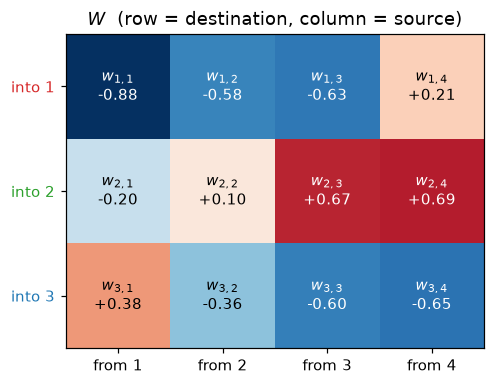

In [5]:
#| label: fig-weight-matrix
#| fig-cap: "The weight matrix $W$ as a heat map. Row $j$ holds the weights into layer-2 node $j$; column $i$ holds the weights out of layer-1 node $i$."
fig, ax = plt.subplots(figsize=(6.4, 3.6))
vmax = np.abs(W).max()
ax.imshow(W, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
for j in range(N_OUT):
    for i in range(N_IN):
        ax.text(i, j, rf"$w_{{{j+1},{i+1}}}$" + f"\n{W[j, i]:+.2f}",
                ha="center", va="center", fontsize=10,
                color="white" if abs(W[j, i]) > 0.6 * vmax else "black")
ax.set_xticks(range(N_IN), [f"from {i+1}" for i in range(N_IN)])
ax.set_yticks(range(N_OUT), [f"into {j+1}" for j in range(N_OUT)])
for j, c in enumerate(ROW_COLORS):
    ax.get_yticklabels()[j].set_color(c)
ax.set_title(r"$W$  (row = destination, column = source)")
plt.tight_layout(); plt.show()

## 3. Activation functions

The activation $f$ is applied **element-wise** to each node's pre-activation. Here are the ones from my notes, each with the derivative that backpropagation will need later:

| Name | $f(x)$ | $f'(x)$ |
|---|---|---|
| Sigmoid | $\sigma(x) = \dfrac{1}{1+e^{-x}}$ | $\sigma(x)\,\big(1-\sigma(x)\big)$ |
| Tanh | $\tanh x = \dfrac{e^{x}-e^{-x}}{e^{x}+e^{-x}}$ | $1-\tanh^2 x$ |
| Linear | $kx$ | $k$ |
| Step | $1$ if $x \ge 0$, else $0$ | $0$ (undefined at $0$) |
| Saturating linear ("logic threshold") | $\min\!\big(\max(x,-L),\,L\big)$ | $1$ if $\lvert x\rvert<L$, else $0$ |
| ReLU | $\max(0, x)$ | $1$ if $x>0$, else $0$ |
| Leaky ReLU | $x$ if $x \ge 0$, else $c\,x$ | $1$ if $x \ge 0$, else $c$ |
| ELU | $x$ if $x \ge 0$, else $\alpha\,(e^{x}-1)$ | $1$ if $x \ge 0$, else $\alpha e^{x}$ |
| GELU | $x\,\Phi(x)$, $\;\Phi(x)=\tfrac12\big(1+\operatorname{erf}(x/\sqrt2)\big)$ | $\Phi(x) + x\,\varphi(x)$ |

Here $\Phi$ is the standard normal CDF and $\varphi$ its density. For the plots: $k=1$, $L=4$ (the limit drawn in my sketch), $c=0.1$ (exaggerated so the slope is visible; $0.01$ is common), and $\alpha=1$.

In [6]:
_erf = np.vectorize(math.erf)

def sigmoid(x):    return 1.0 / (1.0 + np.exp(-x))
def d_sigmoid(x):  s = sigmoid(x); return s * (1.0 - s)

def d_tanh(x):     return 1.0 - np.tanh(x) ** 2

def linear(x, k=1.0):    return k * x
def d_linear(x, k=1.0):  return np.full_like(x, k)

def step(x):       return (x >= 0).astype(float)
def d_step(x):     return np.zeros_like(x)            # undefined at x = 0

def sat_linear(x, L=4.0):    return np.clip(x, -L, L)
def d_sat_linear(x, L=4.0):  return (np.abs(x) < L).astype(float)

def relu(x):       return np.maximum(0.0, x)
def d_relu(x):     return (x > 0).astype(float)

def leaky_relu(x, c=0.1):    return np.where(x >= 0, x, c * x)
def d_leaky_relu(x, c=0.1):  return np.where(x >= 0, 1.0, c)

def elu(x, alpha=1.0):       return np.where(x >= 0, x, alpha * (np.exp(np.minimum(x, 0)) - 1))
def d_elu(x, alpha=1.0):     return np.where(x >= 0, 1.0, alpha * np.exp(np.minimum(x, 0)))

def Phi(x):        return 0.5 * (1.0 + _erf(x / np.sqrt(2.0)))
def phi(x):        return np.exp(-0.5 * x**2) / np.sqrt(2.0 * np.pi)
def gelu(x):       return x * Phi(x)
def d_gelu(x):     return Phi(x) + x * phi(x)

ACTIVATIONS = [
    ("Sigmoid",                       sigmoid,    d_sigmoid),
    ("Tanh",                          np.tanh,    d_tanh),
    ("Linear ($k=1$)",                linear,     d_linear),
    ("Step",                          step,       d_step),
    ("Saturating linear ($L=4$)",     sat_linear, d_sat_linear),
    ("ReLU",                          relu,       d_relu),
    ("Leaky ReLU ($c=0.1$)",          leaky_relu, d_leaky_relu),
    ("ELU ($\\alpha=1$)",             elu,        d_elu),
    ("GELU",                          gelu,       d_gelu),
]

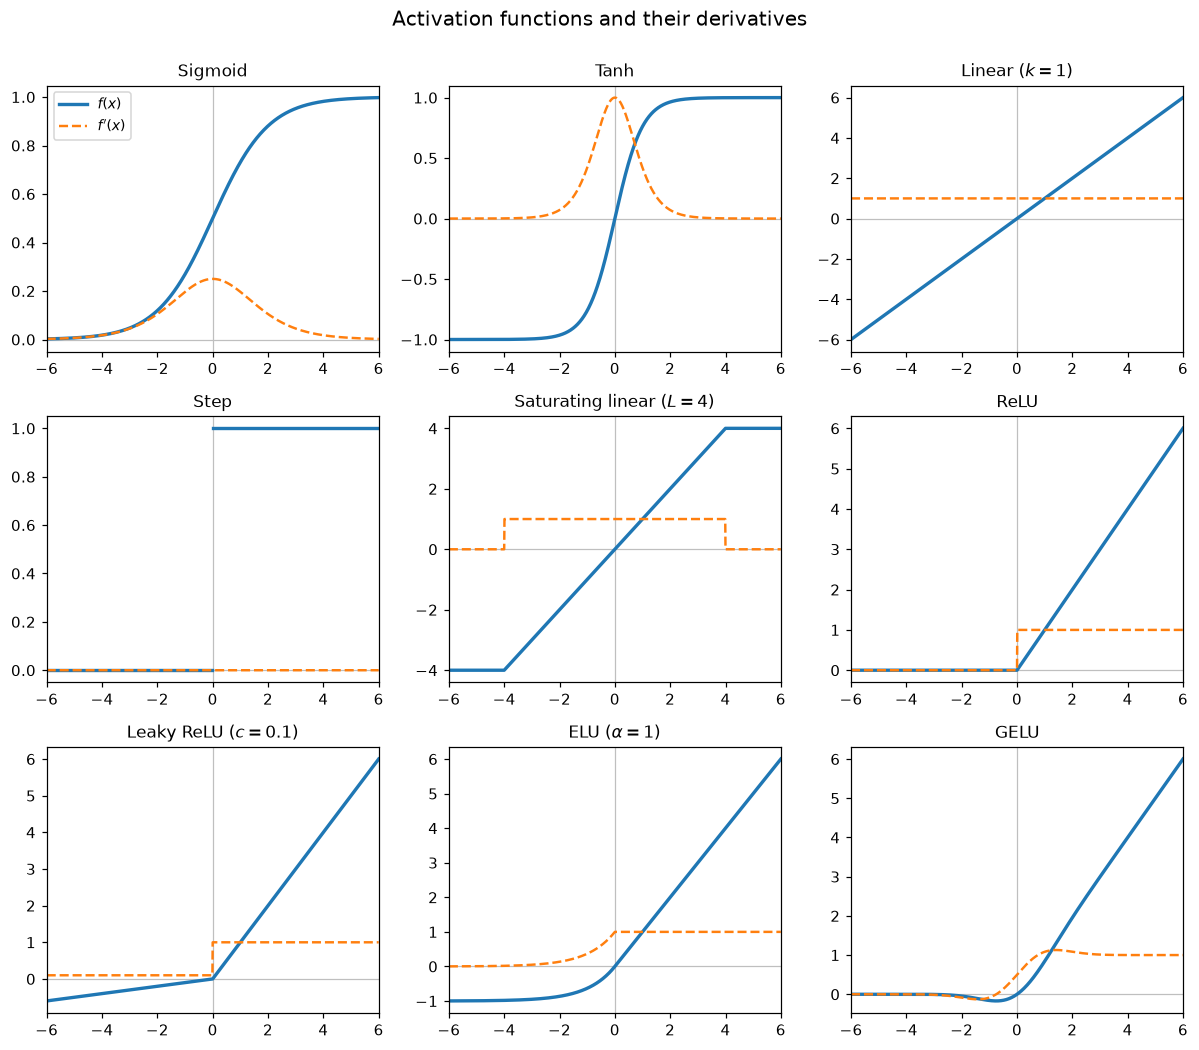

In [7]:
#| label: fig-activations
#| fig-cap: "Each activation function (solid) with its derivative (dashed). The derivative is what gradient descent sees during training."
x = np.linspace(-6, 6, 1201)
fig, axes = plt.subplots(3, 3, figsize=(11, 9.5))
for ax, (name, fn, dfn) in zip(axes.ravel(), ACTIVATIONS):
    ax.axhline(0, color="0.75", lw=0.8); ax.axvline(0, color="0.75", lw=0.8)
    if fn is step:   # draw the jump as a jump, not a sloped line
        ax.plot(x[x < 0], fn(x[x < 0]), color="C0", lw=2.2, label="$f(x)$")
        ax.plot(x[x >= 0], fn(x[x >= 0]), color="C0", lw=2.2)
    else:
        ax.plot(x, fn(x), color="C0", lw=2.2, label="$f(x)$")
    ax.plot(x, dfn(x), color="C1", lw=1.6, ls="--", label="$f'(x)$")
    ax.set_title(name, fontsize=11)
    ax.set_xlim(-6, 6)
axes[0, 0].legend(loc="upper left", fontsize=9)
fig.suptitle("Activation functions and their derivatives", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

**What to read here.**

- **Sigmoid and tanh saturate.** Far from 0 they flatten out and their derivatives go to 0. Through many layers those near-zero derivatives multiply together, which is the *vanishing gradient* problem. Tanh is zero-centered and its slope at 0 is 1 (sigmoid's is only $\tfrac14$).
- **Step has zero derivative everywhere** (and none at the jump), so gradient descent gets no signal through it. That's why smooth or piecewise-linear activations replaced it. The **saturating linear** function is a compromise: linear in the middle, flat outside $\pm L$, so it also stops passing gradient once it saturates.
- **Linear** adds nothing on its own: stacking linear layers gives another linear map ($W_2W_1$ is just one matrix). Non-linearity is what lets depth help.
- **ReLU** is cheap and doesn't saturate for $x>0$. Its derivative is exactly 0 for $x<0$, so a node that's always negative stops learning (a "dead" ReLU). **Leaky ReLU** keeps a small slope $c$ there, and **ELU** curves smoothly toward $-\alpha$.
- **GELU** is a smooth ReLU: it weights $x$ by $\Phi(x)$, the probability that a standard normal falls below $x$. It dips slightly below 0 around $x \approx -0.75$, and it's the default in Transformer models.

## 4. Softmax — the output layer for classification

Softmax is different from the activations above: it maps a whole **vector** to a vector, so each output depends on *all* the inputs:

$$\sigma(\mathbf{a})_i = \frac{e^{a_i}}{\sum_{j=1}^{k} e^{a_j}}, \qquad \sigma(\mathbf{a})_i > 0, \quad \sum_{i=1}^{k} \sigma(\mathbf{a})_i = 1.$$

So the outputs can be read as **class probabilities**. Adding the same constant to every $a_i$ leaves the result unchanged, since $e^{c}$ cancels top and bottom. Implementations use this and subtract $\max_i a_i$ first so that $e^{a_i}$ can't overflow.

To finish the forward pass, I feed the layer-2 pre-activations $\mathbf{a}_2$ from section 2 into softmax, treating the three layer-2 nodes as three classes.

In [8]:
def softmax(a):
    """sigma(a)_i = exp(a_i) / sum_j exp(a_j), computed stably by shifting by max(a)."""
    e = np.exp(a - a.max())
    return e / e.sum()

p = softmax(a2)
print("a2            =", a2.round(4))
print("softmax(a2)   =", p.round(4), "  sum =", p.sum().round(6))
print("shift by +100 =", softmax(a2 + 100).round(4), " (unchanged)")
print("predicted class:", int(p.argmax()) + 1)

a2            = [-0.4693  0.6711 -0.292 ]
softmax(a2)   = [0.1879 0.5878 0.2243]   sum = 1.0
shift by +100 = [0.1879 0.5878 0.2243]  (unchanged)
predicted class: 2


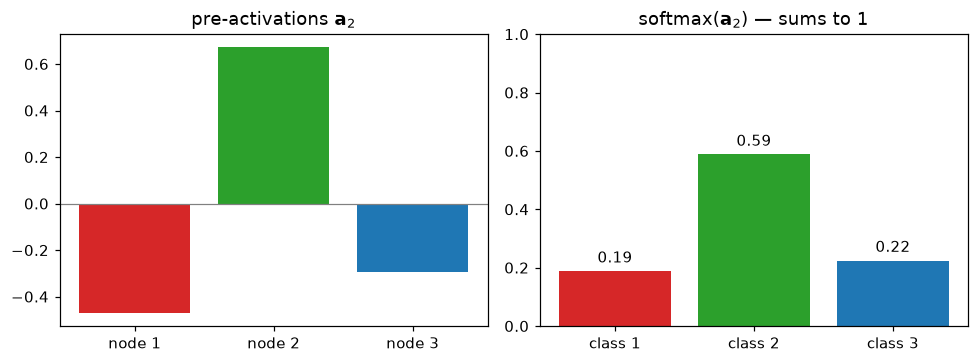

In [9]:
#| label: fig-softmax
#| fig-cap: "Softmax turns the three layer-2 pre-activations (left) into positive values that sum to 1 (right)."
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
idx = np.arange(1, N_OUT + 1)
ax1.bar(idx, a2, color=ROW_COLORS); ax1.axhline(0, color="0.5", lw=0.8)
ax1.set_title(r"pre-activations $\mathbf{a}_2$"); ax1.set_xticks(idx, [f"node {j}" for j in idx])
ax2.bar(idx, p, color=ROW_COLORS); ax2.set_ylim(0, 1)
for j, v in zip(idx, p):
    ax2.text(j, v + 0.03, f"{v:.2f}", ha="center")
ax2.set_title(r"softmax$(\mathbf{a}_2)$ — sums to 1"); ax2.set_xticks(idx, [f"class {j}" for j in idx])
plt.tight_layout(); plt.show()

## Acknowledgment

This notebook accompanies my notes for **24-887 — Machine Learning & Artificial Intelligence for Engineers**, taught by Professor Levent Burak Kara as part of Carnegie Mellon University's [AI Engineering Fundamentals](https://www.cmu.edu/online/ai-engineering-fundamentals) graduate certificate. Credit for the course material goes to the instructor and CMU; the code and any errors here are my own.